# M6: Threshold cascade

**Paper section covered:** 5.2 (Resistance to Cascade of Failure Propagation), Figs. 12, 13 and 14

## Goal
1. **Reproduce** the paper's cascade experiment: fail the biggest hub (ATL) and let failures spread; sweep the breakdown threshold; find the critical threshold.
2. **Explain the transition:** why does the cascade flip from total collapse to a small, contained failure at one specific threshold?
3. **Test the paper's worst-case claim.** The paper starts every cascade at ATL, "as a worst-case scenario". We start a cascade from **every airport** and ask which airports are really the most dangerous, and whether the conclusions depend on the starting point.
4. **Check robustness** to the model's assumptions (identical thresholds) and ask whether the fragility is a property of the degree sequence (null models).

## What the paper does and claims
- **Model:** a node fails if "it loses a fraction of its neighbors exceeding the breakdown threshold". Start: the highest-degree node (ATL), "a worst-case scenario". Sweep the threshold from 0.05 to 0.50.
- **Fig. 13:** a sharp transition. For a threshold **at most 0.15**, 100% of the 541 nodes fail, in 14 steps (Fig. 12). For **0.20 or more** the failure stays contained: 7% of nodes, 3 steps, 40 nodes (Fig. 14); about 6% for thresholds of 0.25 and above.
- **Conclusion:** the critical threshold "lies between 0.15 and 0.20"; "as the critical threshold is on the lower side, it implies high fragility such that if one major hub (e.g., ATL, ORD, DFW) fails, it can quickly trigger cascading shutdowns, which in turn can disrupt other hubs and eventually the entire USFN".

## Plan
| Part | Content |
|---|---|
| A | Reproduce Figs. 12 to 14 and who fails when |
| B | Why the critical threshold is where it is |
| C | Every airport as the origin: who is really the most dangerous? |
| D | Heterogeneous thresholds |
| E | Null models: is this the degree sequence? |
| F | Verdict |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn
import cascade as cs
import nullmodels as nm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 25)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2"

airports, routes = usfn.load_openflights()
G = usfn.build_country_network(airports, routes)
C = cs.Cascade(G)
N = C.n
nodes = C.nodes
deg = C.deg
pos = {n: (G.nodes[n]["lon"], G.nodes[n]["lat"]) for n in nodes}
atl = C.idx["ATL"]
assert N == 541 and deg[atl] == 153
rng = np.random.default_rng(2025)
print(f"USFN: {N} nodes; highest-degree airport {nodes[int(deg.argmax())]} ({deg.max()} connections)")

USFN: 541 nodes; highest-degree airport ATL (153 connections)


## Part A. Reproducing the paper

### A1. The model, and one convention that matters
At every step each surviving airport looks at the fraction of its neighbours that have failed. If that fraction is **at least** the breakdown threshold t, it fails too. Failures spread in synchronous rounds until nothing new fails. (This is the standard fractional-threshold cascade of Watts, 2002.)

The paper's wording is "exceeding the threshold", which could mean strictly greater (`>`) or greater-or-equal (`>=`). It matters because fractions like 1/5 = 0.20 occur often with small degrees. We test both against the paper's reported numbers: at threshold 0.20, **40 nodes (7%)**; for thresholds of 0.25 and above, **about 6%**.

In [2]:
rows = []
for rule in [">=", ">"]:
    for t in [0.15, 0.20, 0.25]:
        n_f, rounds = C.size("ATL", t, rule)
        rows.append({"rule": f"fails when failed/degree {rule} t", "threshold": t, "failed airports": n_f, "fraction": round(n_f / N, 3), "steps (frames incl. step 0)": rounds + 1})
conv = pd.DataFrame(rows)
paper_ref = {0.15: "541 (100%), 14 steps", 0.20: "40 (7%), 3 steps", 0.25: "about 6%"}
conv["paper"] = conv.threshold.map(paper_ref)
conv.style.hide(axis="index")

rule,threshold,failed airports,fraction,steps (frames incl. step 0),paper
fails when failed/degree >= t,0.150000,541,1.000000,14,"541 (100%), 14 steps"
fails when failed/degree >= t,0.200000,40,0.074000,3,"40 (7%), 3 steps"
fails when failed/degree >= t,0.250000,33,0.061000,3,about 6%
fails when failed/degree > t,0.150000,541,1.000000,14,"541 (100%), 14 steps"
fails when failed/degree > t,0.200000,33,0.061000,3,"40 (7%), 3 steps"
fails when failed/degree > t,0.250000,25,0.046000,3,about 6%


**The `>=` rule reproduces the paper** at all three thresholds (541 failed in 14 frames at 0.15; exactly 40 failed, fraction 0.07, in 3 frames at 0.20; 33 failed = 6.1% at 0.25). The strict `>` rule gives 33 and 25 failures instead, which does not match. All results below use `>=`.

### A2. Fig. 13: the critical breakdown threshold
We run the cascade from ATL for thresholds from 0.05 to 0.50 in steps of 0.005. (The cascade is deterministic, so the paper's "average fraction failed" has no averaging to do from a single origin; in Part C we average over all possible origins, which is one natural reading.)

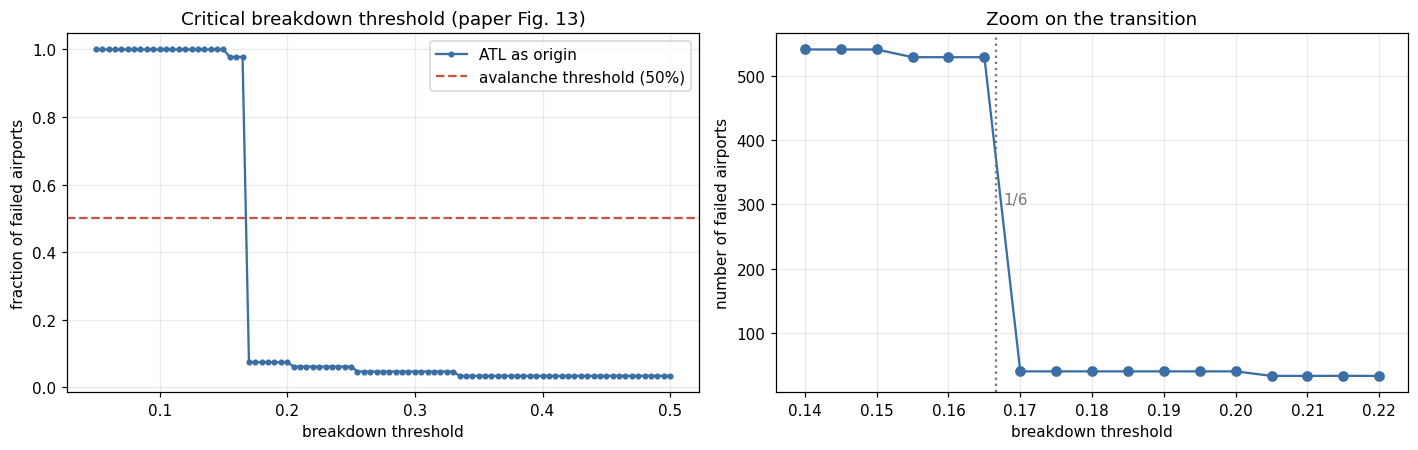

threshold,failed,rounds,fraction
0.050000,541,8,1.000
0.100000,541,9,1.000
0.150000,541,13,1.000
0.160000,529,14,0.978
0.165000,529,14,0.978
0.170000,40,2,0.074
0.200000,40,2,0.074
0.250000,33,2,0.061
0.300000,25,2,0.046
0.400000,18,2,0.033


Last threshold with an avalanche (>= 50% failed): 0.165; first threshold without: 0.17


In [3]:
grid = np.round(np.arange(0.05, 0.5001, 0.005), 3)
atl_sweep = pd.DataFrame([{"threshold": t, "failed": int((r := C.run([atl], C.need(t)))[0].sum()), "rounds": r[2]} for t in grid])
atl_sweep["fraction"] = atl_sweep.failed / N

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(atl_sweep.threshold, atl_sweep.fraction, "o-", ms=3, color=BLUE, label="ATL as origin")
ax.axhline(0.5, color=RED, ls="--", label="avalanche threshold (50%)")
ax.set_xlabel("breakdown threshold"); ax.set_ylabel("fraction of failed airports"); ax.set_title("Critical breakdown threshold (paper Fig. 13)"); ax.legend()
ax = axes[1]
z = atl_sweep[(atl_sweep.threshold >= 0.14) & (atl_sweep.threshold <= 0.22)]
ax.plot(z.threshold, z.failed, "o-", color=BLUE)
ax.axvline(1 / 6, color=GREY, ls=":"); ax.text(1 / 6 + 0.001, 300, "1/6", color=GREY)
ax.set_xlabel("breakdown threshold"); ax.set_ylabel("number of failed airports"); ax.set_title("Zoom on the transition")
plt.tight_layout(); plt.show()

key = atl_sweep[atl_sweep.threshold.isin([0.05, 0.10, 0.15, 0.16, 0.165, 0.17, 0.20, 0.25, 0.30, 0.40, 0.50])]
display(key.style.hide(axis="index").format({"fraction": "{:.3f}"}))
full = atl_sweep[atl_sweep.failed >= 0.5 * N].threshold.max(); small = atl_sweep[atl_sweep.failed < 0.5 * N].threshold.min()
print(f"Last threshold with an avalanche (>= 50% failed): {full}; first threshold without: {small}")

**The sharp transition reproduces:** total collapse at the lowest thresholds, then a cliff, then a small contained failure that shrinks slowly as the threshold rises (40 airports at 0.17 to 0.20, 33 at about 0.22 to 0.25, 25 at 0.30, 18 at 0.40 and above). The paper locates the cliff "between 0.15 and 0.20"; here it can be pinned down much more precisely: **between 0.165 and 0.170, essentially at 1/6**. Part B explains why 1/6.

### A3. Figs. 12 and 14: the cascade, frame by frame
Each panel is the network after one more round of failures: red = failed so far, dark = failed in this round, light = alive. The paper's own layout is not specified, so we use the airports' real coordinates.

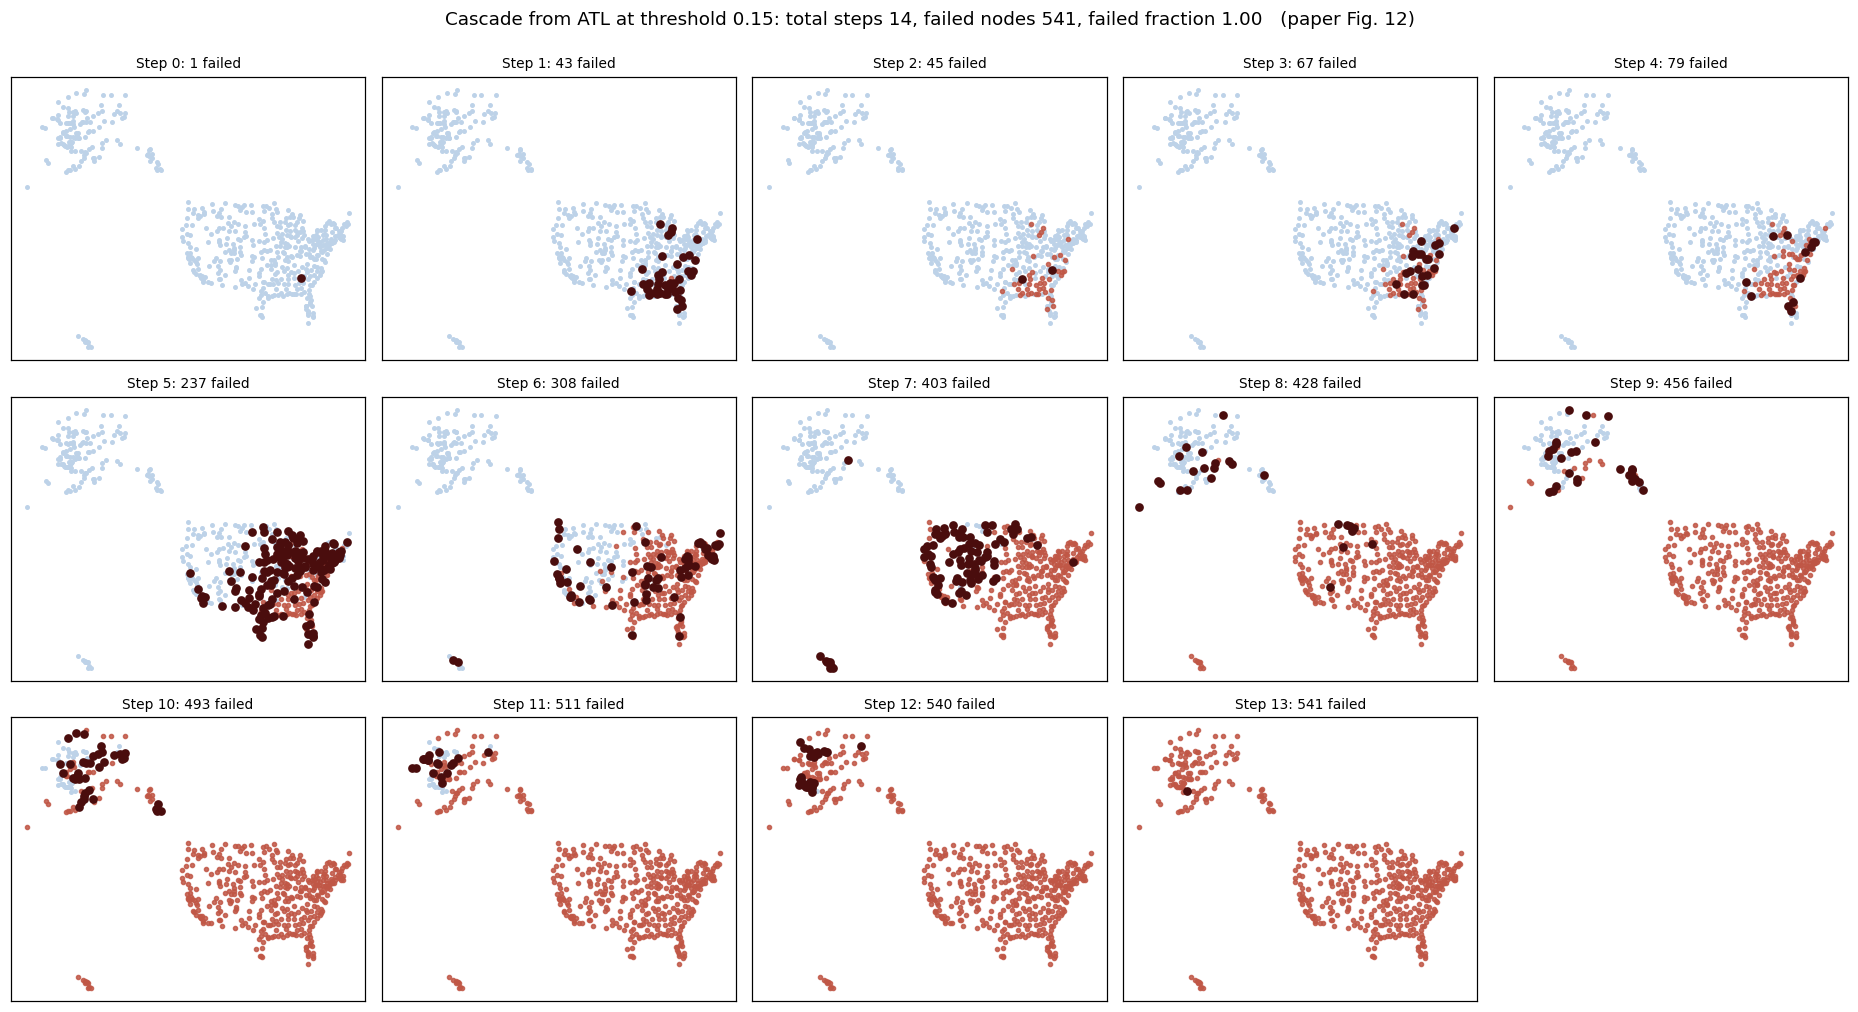

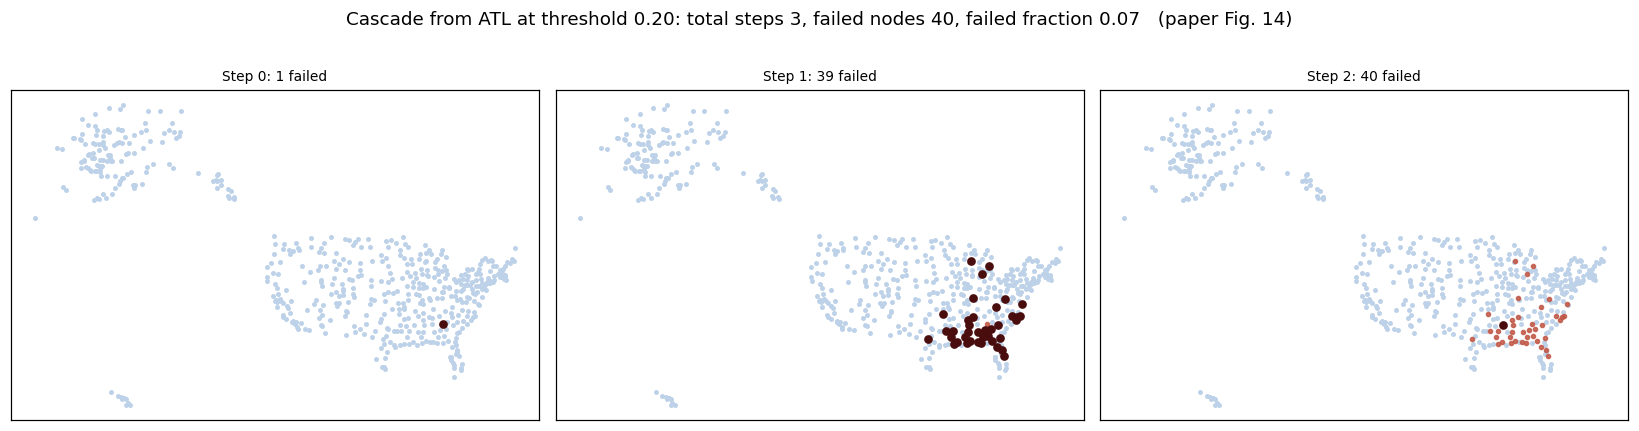

In [4]:
def draw_frame(ax, step_arr, k, title):
    alive = step_arr < 0; failed_prev = (step_arr >= 0) & (step_arr < k); new = step_arr == k
    xs = np.array([pos[n][0] for n in nodes]); ys = np.array([pos[n][1] for n in nodes])
    ax.scatter(xs[alive | (step_arr > k)], ys[alive | (step_arr > k)], s=5, color="#bdd2e8", zorder=1)
    ax.scatter(xs[failed_prev], ys[failed_prev], s=7, color=RED, alpha=0.85, zorder=2)
    ax.scatter(xs[new], ys[new], s=22, color="#4a0d0d", zorder=3)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

f15, s15, r15 = C.run([atl], C.need(0.15))
fig, axes = plt.subplots(3, 5, figsize=(17, 9.2))
for k in range(r15 + 1):
    draw_frame(axes.ravel()[k], s15, k, f"Step {k}: {int(((s15 >= 0) & (s15 <= k)).sum())} failed")
for ax in axes.ravel()[r15 + 1:]: ax.axis("off")
fig.suptitle(f"Cascade from ATL at threshold 0.15: total steps {r15 + 1}, failed nodes {int(f15.sum())}, failed fraction {f15.mean():.2f}   (paper Fig. 12)", y=0.995)
plt.tight_layout(); plt.show()

f20, s20, r20 = C.run([atl], C.need(0.20))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for k in range(r20 + 1): draw_frame(axes[k], s20, k, f"Step {k}: {int(((s20 >= 0) & (s20 <= k)).sum())} failed")
fig.suptitle(f"Cascade from ATL at threshold 0.20: total steps {r20 + 1}, failed nodes {int(f20.sum())}, failed fraction {f20.mean():.2f}   (paper Fig. 14)", y=1.02)
plt.tight_layout(); plt.show()

**Fig. 12 and Fig. 14 reproduce exactly in their reported statistics** (14 frames and 541 failures at 0.15; 3 frames, 40 failures and fraction 0.07 at 0.20).

### A4. Who fails in which round? (threshold 0.15)

In [5]:
rows = []
for k in range(r15 + 1):
    ids = np.where(s15 == k)[0]
    d = deg[ids]
    rows.append({"round": k, "newly failed": len(ids), "median degree": float(np.median(d)), "max degree": int(d.max()),
                 "large hubs (degree >= 100) failing": ", ".join(nodes[i] for i in ids if deg[i] >= 100)})
rounds_df = pd.DataFrame(rows); rounds_df.insert(2, "cumulative", np.cumsum(rounds_df["newly failed"]))
rounds_df.style.hide(axis="index")

round,newly failed,cumulative,median degree,max degree,large hubs (degree >= 100) failing
0,1,1,153.000000,153,ATL
1,42,43,3.000000,6,
2,2,45,55.500000,110,CLT
3,22,67,9.000000,13,
4,12,79,75.000000,149,"ORD, DTW, DFW, IAH"
5,158,237,7.000000,81,
6,71,308,2.000000,149,"LAS, MSP, DEN"
7,95,403,2.000000,34,
8,25,428,1.000000,12,
9,28,456,2.000000,18,


**Reading this.** The cascade has a clear two-level structure:
- **Round 1:** 42 of ATL's neighbours fail at once, all of them *small* airports (degree 6 or less), because each of them lost one neighbour out of at most 6, which is at least 15%.
- **Rounds 2 to 6:** the big hubs fall one after another (CLT in round 2; ORD, DTW, DFW, IAH in round 4; LAS, MSP, DEN in round 6). They fall *because* so many of their small neighbours have already failed, not because they are directly connected to ATL. The single largest wave is round 5: 158 medium-sized airports (median degree 7, up to 81) tip right after the round-4 hubs go.
- **Rounds 7 to 13:** a long tail of small airports (median degree 2) whose few remaining neighbours have failed.

Geographically (Fig. 12), the cascade sweeps from the Southeast through the Midwest and the West, reaches Hawaii around round 6 to 7, and ends in **Alaska** (rounds 8 to 13): the Alaskan network, which hangs off the mainland by a few links, is the last to fall.

So the paper's story ("a major hub fails, then other hubs fail, then the whole network") is right for this origin, with one precision: **hubs fail because their spokes failed first**.

## Part B. Why does the transition sit at 1/6?
In this model a node of degree d fails after a *single* failed neighbour exactly when 1/d >= t, i.e. d <= 1/t. At t = 0.16 that includes every airport with degree up to 6; at t = 0.17 only those up to 5. The cliff between 0.165 and 0.170 is therefore the point where **airports of degree 6 stop being tipped by one failed neighbour**. To test that, we make one degree class slightly harder to topple (one extra failed neighbour required) and see what happens to the cascade at t = 0.16.

degree class made harder (one extra failed neighbour needed),airports in the class,airports adjacent to ATL in the class,cascade size at t = 0.16
2,113,7,36
3,61,7,37
4,28,8,36
5,20,7,37
6,13,4,40
7,11,2,529
8,9,5,494
9,11,8,529
10,10,6,529


baseline (nothing changed): cascade size at t = 0.16 = 529


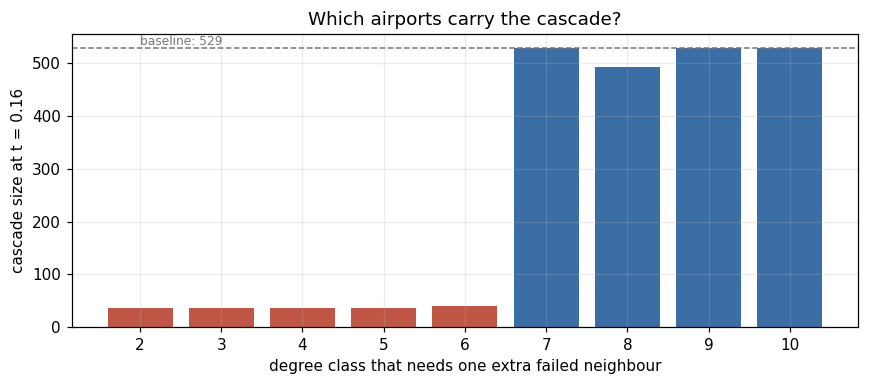

In [6]:
base = C.need(0.16)
rows = []
for d in range(2, 11):
    nd = base.copy(); nd[deg == d] += 1
    rows.append({"degree class made harder (one extra failed neighbour needed)": d, "airports in the class": int((deg == d).sum()),
                 "airports adjacent to ATL in the class": int(sum(deg[j] == d for j in C.nbrs[atl])), "cascade size at t = 0.16": int(C.run([atl], nd)[0].sum())})
imm = pd.DataFrame(rows)
display(imm.style.hide(axis="index"))
print("baseline (nothing changed): cascade size at t = 0.16 =", int(C.run([atl], base)[0].sum()))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(imm.iloc[:, 0].astype(str), imm.iloc[:, 3], color=[RED if v < 100 else BLUE for v in imm.iloc[:, 3]])
ax.axhline(529, color=GREY, ls="--", lw=1); ax.text(0, 535, "baseline: 529", color=GREY, fontsize=8)
ax.set_xlabel("degree class that needs one extra failed neighbour"); ax.set_ylabel("cascade size at t = 0.16"); ax.set_title("Which airports carry the cascade?")
plt.tight_layout(); plt.show()

**Reading this.**
- Raising the bar for **any one** of the degree classes 2, 3, 4, 5 or 6 collapses the cascade from 529 airports to 36 to 40, while raising it for degrees 7 to 10 changes little or nothing (529, 494, 529, 529). So the cascade at t = 0.16 depends on the **whole first wave of ATL's small neighbours** (42 airports of degree 6 or less) being tipped by a single lost link: remove any slice of that wave and the cascade stalls before it reaches the big hubs.
- This makes the cascade **knife-edge**, like a branching process at criticality: ATL's first wave is just enough to tip CLT, which with the second wave tips ORD, DTW, DFW and IAH, and so on. At t just above 1/6 the degree-6 airports drop out of the first wave and the chain breaks: that is the cliff at 1/6, and it is why the transition is so *sharp* (all-or-nothing).
- The paper's critical threshold is therefore not a property of "the hubs" as such: it is set by the **degree structure of the small airports around the origin**. The same logic predicts that origins whose neighbourhoods contain many small airports are the dangerous ones, which Part C tests.

## Part C. Every airport as the origin
The paper starts every cascade at ATL "as a worst-case scenario". That is an assumption, and it can be tested: we start a cascade at each of the 541 airports in turn, for every threshold.

threshold,origins causing an avalanche (>= 50%),median cascade size,mean fraction failed,ATL cascade,largest cascade (origin)
0.050000,37.5% (203 airports),2,0.377000,541,541 (ORD)
0.100000,7.4% (40 airports),1,0.091000,541,541 (ORD)
0.150000,1.7% (9 airports),1,0.025000,541,541 (ATL)
0.170000,0.6% (3 airports),1,0.013000,40,529 (LAS)
0.200000,0.2% (1 airports),1,0.010000,40,529 (LAS)
0.250000,0.0% (0 airports),1,0.006000,33,44 (ANC)
0.300000,0.0% (0 airports),1,0.005000,25,39 (DEN)


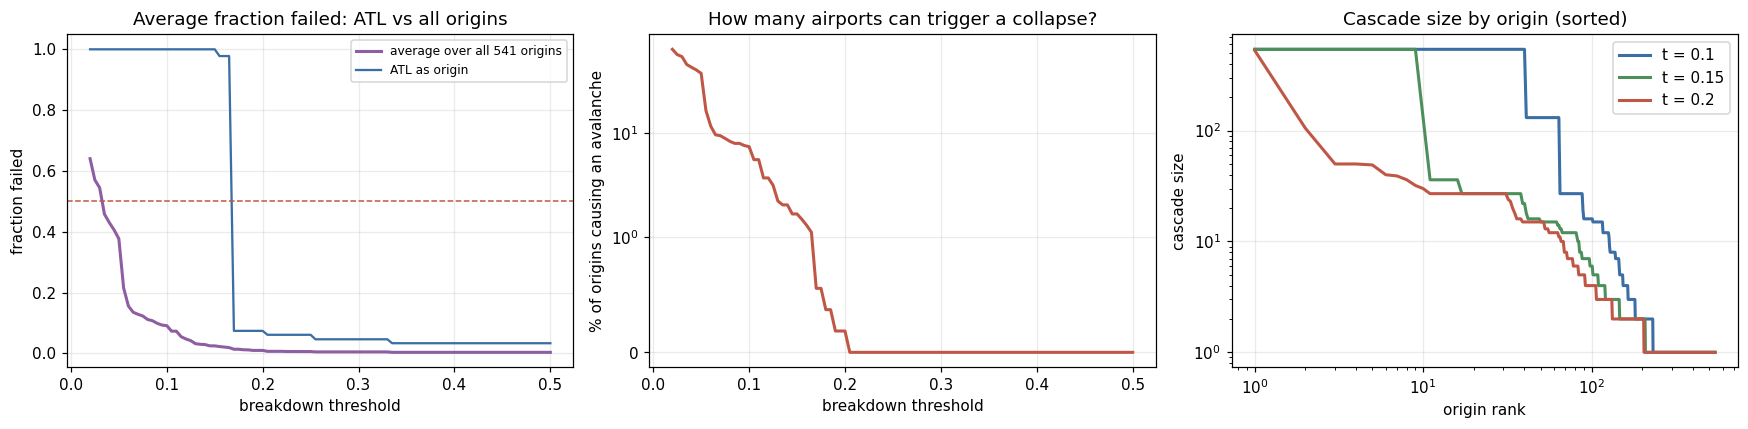

In [7]:
tgrid = np.round(np.arange(0.02, 0.5001, 0.005), 3)
size_mat = np.zeros((N, len(tgrid)), dtype=int)           # cascade size from every origin at every threshold
for gi, t in enumerate(tgrid):
    nd = C.need(t)
    for i in range(N):
        size_mat[i, gi] = C.run([i], nd)[0].sum()
col = {t: gi for gi, t in enumerate(tgrid)}

t_c = np.array([tgrid[np.where(size_mat[i] >= 0.5 * N)[0]].max() if (size_mat[i] >= 0.5 * N).any() else 0.0 for i in range(N)])
size = lambda t: size_mat[:, col[t]]
p_glob = (size_mat >= 0.5 * N).mean(0)                     # share of origins that trigger an avalanche
mean_frac = size_mat.mean(0) / N                           # average fraction failed over all origins

summary = pd.DataFrame({"threshold": [0.05, 0.10, 0.15, 0.17, 0.20, 0.25, 0.30]})
summary["origins causing an avalanche (>= 50%)"] = [f"{p_glob[col[t]]:.1%}  ({int(round(p_glob[col[t]] * N))} airports)" for t in summary.threshold]
summary["median cascade size"] = [int(np.median(size(t))) for t in summary.threshold]
summary["mean fraction failed"] = [round(mean_frac[col[t]], 3) for t in summary.threshold]
summary["ATL cascade"] = [int(size(t)[atl]) for t in summary.threshold]
summary["largest cascade (origin)"] = [f"{size(t).max()} ({nodes[int(size(t).argmax())]})" for t in summary.threshold]
display(summary.style.hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ax = axes[0]
ax.plot(tgrid, mean_frac, color=PURPLE, lw=2, label="average over all 541 origins"); ax.plot(tgrid, size_mat[atl] / N, color=BLUE, lw=1.5, label="ATL as origin")
ax.axhline(0.5, color=RED, ls="--", lw=1); ax.set_xlabel("breakdown threshold"); ax.set_ylabel("fraction failed"); ax.set_title("Average fraction failed: ATL vs all origins"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(tgrid, 100 * p_glob, color=RED, lw=2); ax.set_xlabel("breakdown threshold"); ax.set_ylabel("% of origins causing an avalanche"); ax.set_title("How many airports can trigger a collapse?"); ax.set_yscale("symlog", linthresh=1)
ax = axes[2]
for t, c in [(0.10, BLUE), (0.15, GREEN), (0.20, RED)]:
    v = np.sort(size(t))[::-1]; ax.plot(range(1, N + 1), v, color=c, lw=2, label=f"t = {t}")
ax.set_yscale("log"); ax.set_xscale("log"); ax.set_xlabel("origin rank"); ax.set_ylabel("cascade size"); ax.set_title("Cascade size by origin (sorted)"); ax.legend()
plt.tight_layout(); plt.show()

**Reading this.**
- **Most origins do nothing.** The median cascade size is 1 at every threshold of interest: a typical airport failing alone triggers no further failures, because its neighbours are mostly big hubs that need many failed neighbours.
- **Cascade size is extremely heavy-tailed:** a few airports trigger most of the damage. At t = 0.15 only 9 airports (1.7%) can cause an avalanche; at t = 0.20 only one.
- **ATL is not the worst origin beyond t = 0.16.** At t = 0.17 to 0.20 ATL causes 40 failures (7%) while some other airports still cause a **98% collapse**. ATL is among the worst origins up to about 0.16 (at t = 0.15 nine airports can each collapse the whole network, ATL being one of them), but not above.

### C2. Each airport's own critical threshold
For every airport we find the largest threshold at which its failure still triggers an avalanche. The **network-level** critical threshold, above which *no single failure* can cause an avalanche, is the maximum over airports.

In [8]:
bc = nx.betweenness_centrality(G)
bc_rank = pd.Series(bc).rank(ascending=False, method="min")
deg_rank = pd.Series(dict(zip(nodes, deg))).rank(ascending=False, method="min")
share_small = np.array([np.mean(deg[C.nbrs[i]] <= 6) for i in range(N)])          # share of an airport's neighbours that are small (degree <= 6)
n_small = np.array([int(np.sum(deg[C.nbrs[i]] <= 6)) for i in range(N)])
dang = pd.DataFrame({"airport": nodes, "city": [G.nodes[n]["city"] for n in nodes], "degree": deg, "degree rank": deg_rank.values.astype(int),
                     "betweenness rank": bc_rank.values.astype(int), "small neighbours (deg <= 6)": n_small, "share small": share_small,
                     "own critical threshold": t_c, "cascade at 0.15": size(0.15), "cascade at 0.20": size(0.20)})
top = dang.sort_values(["own critical threshold", "cascade at 0.20"], ascending=False).head(12)
display(top.style.hide(axis="index").format({"own critical threshold": "{:.3f}", "share small": "{:.2f}"}))
net_tc = t_c.max()
print(f"Network-level critical threshold (largest own threshold): {net_tc:.3f}, reached by {nodes[int(t_c.argmax())]}")
print(f"ATL's own critical threshold: {t_c[atl]:.3f}  (rank {int((t_c > t_c[atl]).sum()) + 1} of {N}); the paper's stated range 0.15 to 0.20 is the range for the worst origin only at its upper end")
from scipy.stats import spearmanr
pos_tc = t_c > 0
print("Spearman correlation of the own critical threshold (airports with one > 0) with:",
      {"degree": round(spearmanr(deg[pos_tc], t_c[pos_tc]).statistic, 2), "betweenness": round(spearmanr([bc[n] for n in np.array(nodes)[pos_tc]], t_c[pos_tc]).statistic, 2),
       "number of small neighbours": round(spearmanr(n_small[pos_tc], t_c[pos_tc]).statistic, 2), "share of small neighbours": round(spearmanr(share_small[pos_tc], t_c[pos_tc]).statistic, 2)})
print(f"Airports able to cause an avalanche at some threshold >= 0.02: {(t_c > 0).sum()}; at a threshold above 0.15: {(t_c > 0.15).sum()}; above 0.17: {(t_c > 0.17).sum()}")

airport,city,degree,degree rank,betweenness rank,small neighbours (deg <= 6),share small,own critical threshold,cascade at 0.15,cascade at 0.20
LAS,Las Vegas,113,7,10,17,0.15,0.200,541,529
MSP,Minneapolis,117,5,6,26,0.22,0.185,541,30
DFW,Dallas-Fort Worth,138,4,7,39,0.28,0.175,541,39
PIE,St. Petersburg,31,46,78,11,0.35,0.165,541,50
SFB,Sanford,48,33,32,21,0.44,0.165,541,50
ATL,Atlanta,153,1,5,42,0.27,0.165,541,40
FLL,Fort Lauderdale,58,25,38,5,0.09,0.160,541,6
IAH,Houston,101,9,21,21,0.21,0.155,541,23
DEN,Denver,149,2,2,48,0.32,0.150,541,49
ORD,Chicago,149,2,3,35,0.23,0.140,36,32


Network-level critical threshold (largest own threshold): 0.200, reached by LAS
ATL's own critical threshold: 0.165  (rank 4 of 541); the paper's stated range 0.15 to 0.20 is the range for the worst origin only at its upper end


Spearman correlation of the own critical threshold (airports with one > 0) with: {'degree': 0.36, 'betweenness': 0.38, 'number of small neighbours': 0.5, 'share of small neighbours': 0.23}
Airports able to cause an avalanche at some threshold >= 0.02: 346; at a threshold above 0.15: 8; above 0.17: 3


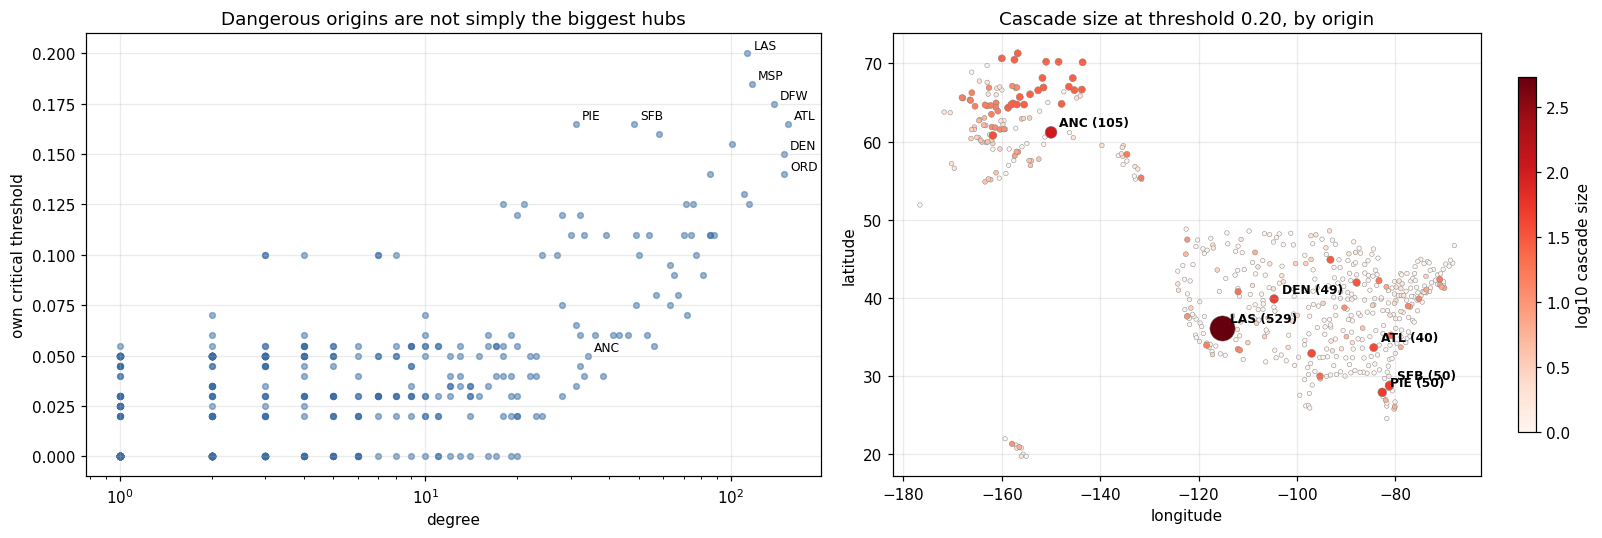

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.scatter(deg, t_c, s=14, alpha=0.5, color=BLUE)
for n in ["LAS", "MSP", "DFW", "PIE", "SFB", "ATL", "ORD", "DEN", "ANC"]:
    ax.annotate(n, (deg[C.idx[n]], t_c[C.idx[n]]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("degree"); ax.set_ylabel("own critical threshold"); ax.set_title("Dangerous origins are not simply the biggest hubs")
ax = axes[1]
order = np.argsort(size(0.20))
sc = ax.scatter([pos[nodes[i]][0] for i in order], [pos[nodes[i]][1] for i in order], s=[8 + 0.5 * size(0.20)[i] for i in order],
                c=[np.log10(size(0.20)[i]) for i in order], cmap="Reds", edgecolor="grey", linewidth=0.3)
for n in ["LAS", "ANC", "SFB", "PIE", "DEN", "ATL"]: ax.annotate(f"{n} ({size(0.20)[C.idx[n]]})", pos[n], xytext=(5, 4), textcoords="offset points", fontsize=8, weight="bold")
ax.set_title("Cascade size at threshold 0.20, by origin"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); plt.colorbar(sc, ax=ax, label="log10 cascade size", shrink=0.8)
plt.tight_layout(); plt.show()

**Reading this.**
- **The most dangerous airport is LAS (Las Vegas)**, with its own critical threshold at 0.20, then MSP (0.185) and DFW (0.175). ATL (0.165) ranks fourth, tied with PIE and SFB. So the highest threshold at which a *single failure can still bring down almost the whole network* is about **0.20**, not 0.15.
- **ORD and DEN, two of the largest hubs, are less dangerous** than ATL (own critical thresholds 0.14 and 0.15 against 0.165), and at t = 0.15 ORD's failure causes only 36 further failures, not a collapse. The paper's list "if one major hub (ATL, ORD, DFW) fails" is therefore not correct as a general statement: **being a major hub is neither necessary nor sufficient** for triggering a collapse.
- **Small airports can be dangerous too:** PIE and SFB (St. Petersburg-Clearwater and Orlando Sanford) have degrees of only 31 and 48 but share ATL's own critical threshold of 0.165, ahead of ORD and DEN.
- **What predicts danger?** See the correlations printed above: the own critical threshold is related to the airport's neighbourhood and not just to its degree; the number of small neighbours is the most informative of the simple measures (Spearman 0.50, against 0.36 for degree and 0.38 for betweenness), consistent with the first-wave mechanism of Part B. The relationship is only moderate, though: LAS, the most dangerous origin, has just 17 small neighbours, so no single simple measure predicts the danger of an origin.
- The paper's choice of ATL is a reasonable representative origin but not the worst case, and the paper's critical threshold (0.15 to 0.20) is essentially the *ATL-specific* threshold (0.165). The conclusion that the network is fragile for thresholds below about 0.17 stands; the claim that it is "resilient above 0.20" does not hold for thresholds in 0.17 to 0.20, where LAS alone collapses it.

## Part D. Do the conclusions depend on all airports having the same threshold?
Real airports do not all tolerate the same fraction of lost links. We give every airport its own threshold, drawn uniformly from [t - w, t + w] around the mean t, for w = 0 (the paper), 0.05 and 0.10, and run 300 random realisations from ATL and from a random origin (Watts' standard test).

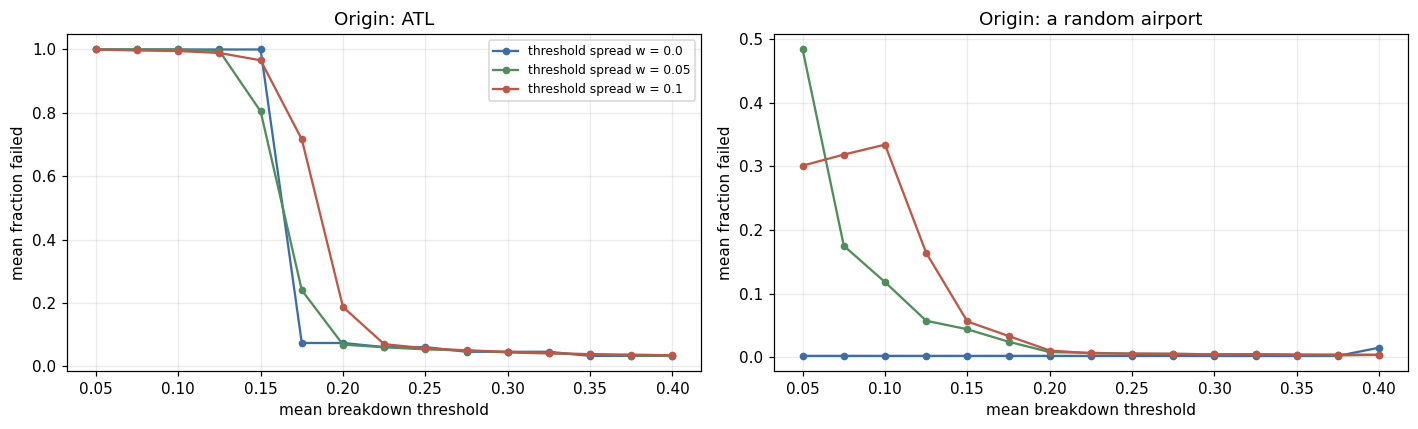

mean threshold,"ATL, w = 0.0: P(avalanche)","ATL, w = 0.05: P(avalanche)","ATL, w = 0.1: P(avalanche)","random origin, w = 0.10: P(avalanche)"
0.05,1.00,1.00,1.00,0.29
0.07,1.00,1.00,1.00,0.30
0.10,1.00,1.00,1.00,0.32
0.12,1.00,1.00,1.00,0.15
0.15,1.00,0.80,0.99,0.04
0.17,0.00,0.19,0.74,0.03
0.20,0.00,0.00,0.14,0.00
0.23,0.00,0.00,0.01,0.00
0.25,0.00,0.00,0.00,0.00
0.28,0.00,0.00,0.00,0.00


In [10]:
def need_vec(thr):
    return np.maximum(np.ceil(thr * deg - 1e-9), 1).astype(np.int64)

tbar = np.round(np.arange(0.05, 0.401, 0.025), 3)
widths = [0.0, 0.05, 0.10]
R = 300
het = {}
for w in widths:
    for origin in ["ATL", "random"]:
        m, p = [], []
        for t in tbar:
            sizes = []
            for _ in range(R if w > 0 else 1):
                thr = rng.uniform(max(t - w, 0.005), t + w, size=N) if w > 0 else np.full(N, t)
                seed = atl if origin == "ATL" else int(rng.integers(N))
                sizes.append(C.run([seed], need_vec(thr))[0].sum())
            sizes = np.array(sizes); m.append(sizes.mean() / N); p.append((sizes >= 0.5 * N).mean())
        het[(w, origin)] = (np.array(m), np.array(p))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, origin in zip(axes, ["ATL", "random"]):
    for w, c in zip(widths, [BLUE, GREEN, RED]):
        ax.plot(tbar, het[(w, origin)][0], "o-", ms=4, color=c, label=f"threshold spread w = {w}")
    ax.set_xlabel("mean breakdown threshold"); ax.set_ylabel("mean fraction failed"); ax.set_title(f"Origin: {'ATL' if origin == 'ATL' else 'a random airport'}")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

tab = pd.DataFrame({"mean threshold": tbar})
for w in widths: tab[f"ATL, w = {w}: P(avalanche)"] = het[(w, "ATL")][1]
tab[f"random origin, w = 0.10: P(avalanche)"] = het[(0.10, "random")][1]
tab.style.hide(axis="index").format(precision=2)

**Reading this.** Giving airports different thresholds **blurs the cliff** but does not remove it. With identical thresholds the avalanche probability from ATL jumps from 1 to 0 between 0.15 and 0.17; with w = 0.10 it falls gradually: 0.99 at 0.15, 0.74 at 0.17, 0.14 at 0.20 and 0.01 at 0.23. Heterogeneity cuts both ways: it lets a few very sensitive airports start collapses at mean thresholds where the identical-threshold model is safe (0.17 to 0.23), and it can also stop a collapse at thresholds where the identical model always fails (w = 0.05 at 0.15: probability 0.80). So the *sharp* critical value 0.15 to 0.20 is partly an artefact of the identical-threshold assumption. A random origin is far less dangerous than ATL at every mean threshold (for example 4% against 99% at 0.15), in line with Part C.

## Part E. Is this a property of the degree sequence? Null models
We repeat the analysis on random networks with the same number of nodes and edges: ER, BA, and **degree-preserving** rewiring of the real network (5 networks each). For each we record the share of origins that can cause an avalanche and the critical threshold for the highest-degree origin (10 networks).

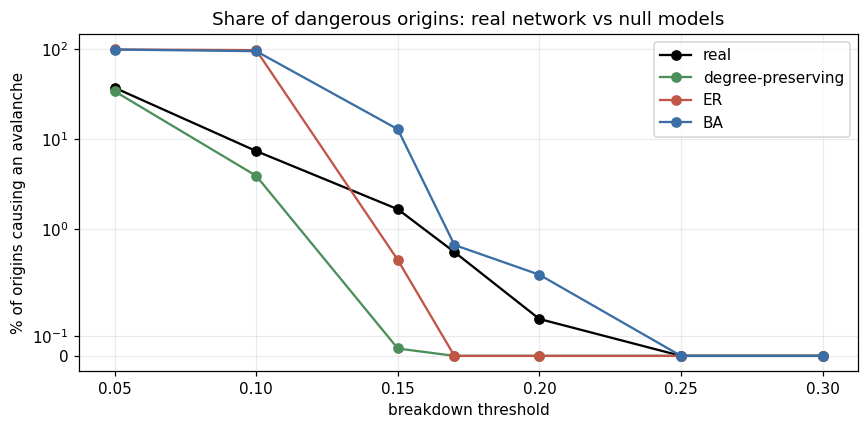

network,critical threshold of the highest-degree origin,% avalanche origins at t = 0.05,% avalanche origins at t = 0.1,% avalanche origins at t = 0.15,% avalanche origins at t = 0.17,% avalanche origins at t = 0.2,% avalanche origins at t = 0.25,% avalanche origins at t = 0.3
real USFN,0.165,37.5,7.4,1.7,0.6,0.2,0.0,0.0
degree-preserving,0.134 (range 0.125 to 0.150),34.3,3.9,0.0,0.0,0.0,0.0,0.0
ER,0.130 (range 0.125 to 0.140),100.0,98.4,0.5,0.0,0.0,0.0,0.0
BA,0.184 (range 0.165 to 0.200),99.9,95.8,12.9,0.7,0.4,0.0,0.0


In [11]:
Gu = nx.Graph(G.edges)
def make(kind, s):
    return {"degree-preserving": lambda: nm.degree_preserving(Gu, 7000 + s), "ER": lambda: nm.er_like(N, G.number_of_edges(), 7000 + s),
            "BA": lambda: nm.ba_like(N, G.number_of_edges(), 7000 + s)}[kind]()

tt = [0.05, 0.10, 0.15, 0.17, 0.20, 0.25, 0.30]
pg = {"real": [p_glob[col[t]] for t in tt]}
hub_tc = {"real": [t_c[atl]]}
tg = np.round(np.arange(0.05, 0.4001, 0.005), 3)
for kind in ["degree-preserving", "ER", "BA"]:
    runs, hubs = [], []
    for s in range(10):
        Cx = cs.Cascade(make(kind, s)); hub = int(np.argmax(Cx.deg))
        ok = [t for t in tg if Cx.run([hub], Cx.need(t))[0].sum() >= 0.5 * Cx.n]; hubs.append(max(ok) if ok else 0.0)
        if s < 5: runs.append([np.mean([Cx.run([i], Cx.need(t))[0].sum() >= 0.5 * Cx.n for i in range(Cx.n)]) for t in tt])
    pg[kind] = np.mean(runs, axis=0); hub_tc[kind] = hubs

fig, ax = plt.subplots(figsize=(8, 4))
for k, c in zip(["real", "degree-preserving", "ER", "BA"], ["black", GREEN, RED, BLUE]):
    ax.plot(tt, 100 * np.array(pg[k]), "o-", color=c, label=k)
ax.set_yscale("symlog", linthresh=0.5); ax.set_xlabel("breakdown threshold"); ax.set_ylabel("% of origins causing an avalanche"); ax.set_title("Share of dangerous origins: real network vs null models"); ax.legend()
plt.tight_layout(); plt.show()

tab = pd.DataFrame({"network": ["real USFN", "degree-preserving", "ER", "BA"],
                    "critical threshold of the highest-degree origin": [f"{hub_tc['real'][0]:.3f}"] + [f"{np.mean(hub_tc[k]):.3f}  (range {min(hub_tc[k]):.3f} to {max(hub_tc[k]):.3f})" for k in ["degree-preserving", "ER", "BA"]]})
for j, t in enumerate(tt): tab[f"% avalanche origins at t = {t}"] = [f"{100 * pg['real'][j]:.1f}"] + [f"{100 * pg[k][j]:.1f}" for k in ["degree-preserving", "ER", "BA"]]
tab.style.hide(axis="index")

**Reading this.**
- The cliff itself is a **generic feature** of this kind of model: every null network also goes from collapse to containment within a narrow band of thresholds (hub-origin critical thresholds of about 0.13 for ER and degree-preserving, 0.18 for BA, against 0.165 for the real network).
- At **very low** thresholds (0.05 to 0.10) the random graphs are *more* fragile than the real network (in ER nearly every airport can trigger a collapse), because in a random graph every node has about 10 neighbours and so is easily tipped; the real network's heterogeneous degrees (many hubs that need many failed neighbours) protect it there.
- At the thresholds that matter (0.15 and above) the real network is **more fragile than the degree-preserving null and ER** and less fragile than BA: at t = 0.15, 1.7% of real origins can cause an avalanche, against 0% for the degree-preserving null, 0.5% for ER and 12.9% for BA; and the real highest-degree origin has a higher critical threshold (0.165) than the degree-matched null (about 0.13). So the specific wiring of the real network makes cascades *more* likely than its degree sequence alone implies.

## Part F. Verdict on the paper's claims

In [12]:
verdict = pd.DataFrame([
    ("Fig. 13 / Fig. 12: threshold at most 0.15 collapses the whole network in 14 steps",
     "Reproduced exactly with the >= rule (541 failed, 14 frames). With > the paper's 0.20 and 0.25 numbers do not reproduce, so the convention is part of the result", "reproduced"),
    ("Fig. 14: threshold 0.20 gives 40 nodes (7%) in 3 steps; about 6% for 0.25 and above",
     f"Reproduced exactly ({int(size(0.20)[atl])} nodes at 0.20, 3 frames; {int(size(0.25)[atl])} = 6.1% at 0.25)", "reproduced"),
    ("Critical threshold lies between 0.15 and 0.20",
     f"For ATL the cliff is between 0.165 and 0.170 (at 1/6), where degree-6 airports stop being tipped by one failed neighbour. This is ATL's own threshold: the worst origin, LAS, has {t_c.max():.3f}", "reproduced and sharpened; not the network's worst case"),
    ("ATL as origin is the worst case",
     f"No: it is worst only up to t = 0.16. At t = 0.20 LAS causes a {size(0.20).max() / N:.0%} collapse versus ATL's {size(0.20)[atl] / N:.0%}; ATL ranks {int((t_c > t_c[atl]).sum()) + 1} by own critical threshold", "not supported"),
    ("If one major hub (ATL, ORD, DFW) fails it triggers a network collapse",
     f"Only some: ATL and DFW can, ORD cannot (own threshold {t_c[C.idx['ORD']]:.2f}; {int(size(0.15)[C.idx['ORD']])} failures at t = 0.15); small airports (PIE, SFB) can. Hub status is neither necessary nor sufficient", "not supported"),
    ("The network is resilient above the critical threshold",
     "True above about 0.20 (no single failure causes an avalanche above t = 0.20), but between 0.17 and 0.20 a single airport (LAS) can still collapse it; with heterogeneous thresholds the cliff blurs", "partly supported"),
    ("(new) What drives the cascade",
     "The cascade is knife-edge: it needs the whole first wave of ATL's small neighbours (making any degree class 2 to 6 harder collapses it 529 -> about 40, degrees 7 to 10 do not matter); hubs fail only after their spokes fail; the cliff also appears in ER, BA and degree-preserving networks", "new finding"),
], columns=["paper's claim", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["paper's claim", "what we find"], **{"text-align": "left", "white-space": "normal"})

paper's claim,what we find,status
Fig. 13 / Fig. 12: threshold at most 0.15 collapses the whole network in 14 steps,"Reproduced exactly with the >= rule (541 failed, 14 frames). With > the paper's 0.20 and 0.25 numbers do not reproduce, so the convention is part of the result",reproduced
Fig. 14: threshold 0.20 gives 40 nodes (7%) in 3 steps; about 6% for 0.25 and above,"Reproduced exactly (40 nodes at 0.20, 3 frames; 33 = 6.1% at 0.25)",reproduced
Critical threshold lies between 0.15 and 0.20,"For ATL the cliff is between 0.165 and 0.170 (at 1/6), where degree-6 airports stop being tipped by one failed neighbour. This is ATL's own threshold: the worst origin, LAS, has 0.200",reproduced and sharpened; not the network's worst case
ATL as origin is the worst case,No: it is worst only up to t = 0.16. At t = 0.20 LAS causes a 98% collapse versus ATL's 7%; ATL ranks 4 by own critical threshold,not supported
"If one major hub (ATL, ORD, DFW) fails it triggers a network collapse","Only some: ATL and DFW can, ORD cannot (own threshold 0.14; 36 failures at t = 0.15); small airports (PIE, SFB) can. Hub status is neither necessary nor sufficient",not supported
The network is resilient above the critical threshold,"True above about 0.20 (no single failure causes an avalanche above t = 0.20), but between 0.17 and 0.20 a single airport (LAS) can still collapse it; with heterogeneous thresholds the cliff blurs",partly supported
(new) What drives the cascade,"The cascade is knife-edge: it needs the whole first wave of ATL's small neighbours (making any degree class 2 to 6 harder collapses it 529 -> about 40, degrees 7 to 10 do not matter); hubs fail only after their spokes fail; the cliff also appears in ER, BA and degree-preserving networks",new finding


## Check against the paper

In [13]:
assert C.size("ATL", 0.15) == (541, 13)                               # 541 failed in 13 rounds = 14 frames (paper Fig. 12)
assert C.size("ATL", 0.20) == (40, 2) and round(40 / N, 2) == 0.07    # paper Fig. 14: 40 nodes, 3 frames, fraction 0.07
assert round(C.size("ATL", 0.25)[0] / N, 2) == 0.06                   # "around 6% for thresholds >= 0.25"
assert C.size("ATL", 0.20, ">")[0] != 40                              # the strict rule does not match the paper
assert C.size("ATL", 0.16)[0] > 0.9 * N and C.size("ATL", 0.17)[0] == 40   # the cliff is between 0.16 and 0.17
assert len(rounds_df) == 14 and rounds_df["newly failed"].sum() == N and rounds_df.loc[1, "newly failed"] == 42
# stepping stones: making degree-5/6 nodes harder kills the cascade, degree 7 does not
imm_idx = imm.set_index(imm.columns[0]); assert imm_idx.loc[6].iloc[-1] < 60 and imm_idx.loc[7].iloc[-1] > 500
# all-origin analysis
assert size(0.20)[C.idx["LAS"]] > 0.9 * N and size(0.20)[atl] == 40                     # LAS, not ATL, is the dangerous origin at 0.20
assert t_c.max() > t_c[atl] and nodes[int(t_c.argmax())] == "LAS" and abs(t_c[atl] - 0.165) < 1e-9
assert p_glob[col[0.25]] == 0 and 0 < p_glob[col[0.20]] < 0.01
assert size(0.15)[C.idx["ORD"]] < 100 and t_c[C.idx["ORD"]] < t_c[atl]                  # ORD does not collapse the network
assert float(np.median(size(0.15))) == 1
# heterogeneity blurs the transition
assert het[(0.10, "ATL")][0][list(tbar).index(0.2)] > het[(0.0, "ATL")][0][list(tbar).index(0.2)]
# nulls: cliff exists in all, degree-preserving hub threshold below the real one
assert np.mean(hub_tc["degree-preserving"]) < hub_tc["real"][0] and pg["ER"][0] > pg["real"][0]
print("All M6 assertions passed.")

All M6 assertions passed.


## Summary and take-aways

- **Reproduced:** Fig. 12, Fig. 13 and Fig. 14 reproduce exactly in their reported statistics: 541 airports fail in 14 frames at threshold 0.15; 40 airports (7%) in 3 frames at 0.20; about 6% at 0.25. The reproduction needs the `>=` rule (fail when the failed fraction is *at least* the threshold); the strict rule does not match the paper.
- **The cliff is at 1/6, and it is knife-edge.** For ATL the transition is between 0.165 and 0.170. Airports of degree 6 or less are tipped by a single failed neighbour while t is at most 1/6; ATL's first wave of 42 such small neighbours is just enough to start the chain, so making *any* degree class from 2 to 6 harder (or letting t pass 1/6, which removes the degree-6 airports from the wave) collapses the cascade from 529 airports to about 40, while degrees 7 to 10 do not matter. Hubs fall in the middle of the cascade, *because* their small neighbours have already failed.
- **ATL is not the worst-case origin.** Running the cascade from every airport shows that the most dangerous origin is **LAS** (critical threshold 0.20; at t = 0.20 it collapses 98% of the network while ATL causes 7%), then MSP and DFW. ORD, one of the largest hubs, cannot collapse the network even at 0.15; small airports (PIE, SFB) can. The paper's "if one major hub (ATL, ORD, DFW) fails the network collapses" is only partly true.
- **Fragility is concentrated:** at t = 0.15 only 9 of 541 airports (1.7%) can trigger a collapse and the median airport triggers nothing; at 0.20 only one can. The network is fragile to a *few specific* failures, not to a typical hub failure.
- **The sharp cliff is partly a modelling artefact:** with heterogeneous thresholds it blurs; and it is generic (null networks show it too). But the real network is more cascade-prone than the degree-preserving null (hub critical threshold 0.165 vs about 0.13; at t = 0.15, 1.7% of origins can collapse it vs 0%).
- **Caveats:** the cascade is purely topological and unweighted (no capacity, no rerouting, no traffic); it describes the 2014 OpenFlights snapshot. The load-based model of M9 adds capacity and rerouting.

**Next:** M7 starts Part B of the project: weighted analysis (what changes when edge weights are used?), including an operated-flights-only weighting to test the codeshare caveat from M0.